In [187]:
!git clone https://github.com/cpoiato/HYDROSIGHT.git /content/HYDROSIGHT

fatal: destination path '/content/HYDROSIGHT' already exists and is not an empty directory.


In [188]:
from pathlib import Path

repo_path = Path("/content/HYDROSIGHT")

print("Repository folder exists:", repo_path.exists())
print("Git metadata exists:", (repo_path / ".git").exists())
print("Current directory:", Path.cwd())

Repository folder exists: True
Git metadata exists: True
Current directory: /content


In [189]:
from google.colab import drive
import json

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [190]:
from pathlib import Path
import sys

ROOT_DIR = Path("/content/HYDROSIGHT")
sys.path.insert(0, str(ROOT_DIR / "src"))
RAW_DIR = ROOT_DIR / "data" / "raw" / "weather"
REPORT_DIR = ROOT_DIR / "reports" / "eda" / "results"
FIGURES_DIR = ROOT_DIR / "reports" / "eda" / "figures"
PROCESSED_DIR = ROOT_DIR / "data" / "processed"

assert RAW_DIR.exists(), f"Folder not found: {RAW_DIR}"
assert RAW_DIR.exists(), f"Folder not found: {RAW_DIR}"

print("Project:", ROOT_DIR)
print("Raw data:", RAW_DIR)


Project: /content/HYDROSIGHT
Raw data: /content/HYDROSIGHT/data/raw/weather


In [191]:
import pandas as pd
from IPython.display import display


files = sorted(RAW_DIR.glob("daily_weather_calgary_1960_2009_*.csv"))

assert files, "No weather snapshots found."

latest_file = files[-1]

df_1960_2009 = pd.read_csv(latest_file)
df_1960_2009.shape

(18263, 7)

In [192]:
files = sorted(RAW_DIR.glob("daily_weather_calgary_2010_2026_*.csv"))

assert files, "No weather snapshots found."

latest_file = files[-1]

df_2010_2026 = pd.read_csv(latest_file)
df_2010_2026.shape

(6209, 7)

In [193]:
df_1960_2009.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18263 entries, 0 to 18262
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         18263 non-null  object 
 1   station_id   18263 non-null  int64  
 2   temp_mean_c  18190 non-null  float64
 3   temp_min_c   18191 non-null  float64
 4   temp_max_c   18190 non-null  float64
 5   precip_mm    18190 non-null  float64
 6   snow_cm      18190 non-null  float64
dtypes: float64(5), int64(1), object(1)
memory usage: 998.9+ KB


In [194]:
df_2010_2026.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6209 entries, 0 to 6208
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         6209 non-null   object 
 1   station_id   6209 non-null   int64  
 2   temp_mean_c  5018 non-null   float64
 3   temp_min_c   5023 non-null   float64
 4   temp_max_c   5041 non-null   float64
 5   precip_mm    5096 non-null   float64
 6   snow_cm      5052 non-null   float64
dtypes: float64(5), int64(1), object(1)
memory usage: 339.7+ KB


In [195]:
df = pd.concat([df_1960_2009, df_2010_2026])
df.shape

(24472, 7)

In [196]:
display("Dataset Information")
df.info()


'Dataset Information'

<class 'pandas.core.frame.DataFrame'>
Index: 24472 entries, 0 to 6208
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         24472 non-null  object 
 1   station_id   24472 non-null  int64  
 2   temp_mean_c  23208 non-null  float64
 3   temp_min_c   23214 non-null  float64
 4   temp_max_c   23231 non-null  float64
 5   precip_mm    23286 non-null  float64
 6   snow_cm      23242 non-null  float64
dtypes: float64(5), int64(1), object(1)
memory usage: 1.5+ MB


In [197]:
display("Dataset Head")
df.head()

'Dataset Head'

,date,station_id,temp_mean_c,temp_min_c,temp_max_c,precip_mm,snow_cm
0,1960-01-01,2205,-12.8,-16.1,-9.4,0.0,0.0
1,1960-01-02,2205,-13.6,-18.3,-8.9,2.5,2.5
2,1960-01-03,2205,-14.2,-24.4,-3.9,5.6,5.6
3,1960-01-04,2205,-6.4,-12.8,0.0,3.8,3.8
4,1960-01-05,2205,-3.1,-11.7,5.6,0.0,0.0


In [198]:
display("Data Description")
df.drop(columns="station_id").describe()

'Data Description'

,temp_mean_c,temp_min_c,temp_max_c,precip_mm,snow_cm
count,23208.000000,23214.000000,23231.000000,23286.000000,23242.000000
mean,4.398798,-1.945184,10.724571,1.145053,0.382205
std,10.963855,10.412947,11.941427,3.797389,1.558827
min,-36.400000,-39.700000,-33.900000,0.000000,0.000000
25%,-2.100000,-7.800000,3.500000,0.000000,0.000000
50%,5.600000,-0.600000,11.800000,0.000000,0.000000
75%,13.200000,6.500000,20.000000,0.400000,0.000000
max,27.300000,19.100000,36.500000,92.600000,48.400000


In [199]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

In [200]:
display("Missing values")
df.isna().sum()

'Missing values'

,0
date,0
station_id,0
temp_mean_c,1264
temp_min_c,1258
temp_max_c,1241
precip_mm,1186
snow_cm,1230


In [201]:
# Analyze missing weather observations by year
weather_columns = [
    "temp_mean_c",
    "temp_min_c",
    "temp_max_c",
    "precip_mm",
    "snow_cm"
]

missing_by_year = (
    df.assign(year=pd.to_datetime(df["date"]).dt.year)
    .groupby("year")[weather_columns]
    .apply(lambda group: group.isna().mean() * 100)
    .round(2)
)

print("=== MISSING WEATHER DATA BY YEAR (%) ===")
display(missing_by_year)

=== MISSING WEATHER DATA BY YEAR (%) ===


,temp_mean_c,temp_min_c,temp_max_c,precip_mm,snow_cm
year,,,,,
1960,0.00,0.00,0.00,0.00,0.00
1961,0.00,0.00,0.00,0.00,0.00
1962,0.00,0.00,0.00,0.00,0.00
1963,0.00,0.00,0.00,0.00,0.00
1964,0.00,0.00,0.00,0.00,0.00
...,...,...,...,...,...
2022,4.66,4.66,4.66,1.10,1.10
2023,0.55,0.55,0.55,0.00,0.00
2024,2.46,2.46,2.46,0.00,0.55


In [202]:
# Review weather data completeness during the modeling period
print("=== WEATHER DATA COMPLETENESS: 2016–2025 ===")

display(
    missing_by_year.loc[2016:2025]
)

=== WEATHER DATA COMPLETENESS: 2016–2025 ===


,temp_mean_c,temp_min_c,temp_max_c,precip_mm,snow_cm
year,,,,,
2016,0.55,0.27,0.27,0.82,1.64
2017,4.93,4.11,0.82,0.55,1.10
2018,2.47,2.47,0.55,0.27,1.10
2019,1.92,1.92,1.92,0.55,6.58
2020,2.19,2.19,2.19,0.27,4.64
2021,4.11,4.11,4.11,0.55,0.82
2022,4.66,4.66,4.66,1.10,1.10
2023,0.55,0.55,0.55,0.00,0.00
2024,2.46,2.46,2.46,0.00,0.55


In [203]:
# Validate daily weather coverage for the modeling period
study_dates = pd.to_datetime(df["date"]).dt.normalize()

expected_dates = pd.date_range(
    start="2016-01-01",
    end="2025-12-31",
    freq="D"
)

observed_dates = pd.DatetimeIndex(
    study_dates[
        study_dates.between("2016-01-01", "2025-12-31")
    ].dropna().unique()
)

missing_dates = expected_dates.difference(observed_dates)

print("=== WEATHER CALENDAR COVERAGE ===")
print("Expected days:", len(expected_dates))
print("Observed unique days:", len(observed_dates))
print("Missing days:", len(missing_dates))
print("Coverage (%):", round(len(observed_dates) / len(expected_dates) * 100, 2))

print("\nMissing days by year:")
print(
    pd.Series(missing_dates.year)
    .value_counts()
    .reindex(range(2016, 2026), fill_value=0)
    .sort_index()
)

=== WEATHER CALENDAR COVERAGE ===
Expected days: 3653
Observed unique days: 3653
Missing days: 0
Coverage (%): 100.0

Missing days by year:
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
2025    0
Name: count, dtype: int64


In [204]:
# Check availability of multiple weather stations per date
study_data = df[
    pd.to_datetime(df["date"]).dt.year.between(2016, 2025)
].copy()

station_coverage = study_data.groupby("date").agg(
    station_count=("station_id", "nunique"),
    observation_count=("station_id", "size")
)

print("=== WEATHER STATION COVERAGE ===")
print("Stations in dataset:", study_data["station_id"].nunique())
print("Days with multiple stations:",
      (station_coverage["station_count"] > 1).sum())
print("Maximum stations per day:",
      station_coverage["station_count"].max())
print("Duplicate station-date records:",
      study_data.duplicated(subset=["station_id", "date"]).sum())

=== WEATHER STATION COVERAGE ===
Stations in dataset: 1
Days with multiple stations: 0
Maximum stations per day: 1
Duplicate station-date records: 0


In [205]:
# Analyze consecutive missing weather observations
weather_columns = [
    "temp_mean_c",
    "temp_min_c",
    "temp_max_c",
    "precip_mm",
    "snow_cm"
]

study_data = df[
    pd.to_datetime(df["date"]).dt.year.between(2016, 2025)
].sort_values("date")

print("=== CONSECUTIVE MISSING OBSERVATIONS ===")

for column in weather_columns:
    missing = study_data[column].isna()

    groups = (missing != missing.shift()).cumsum()
    missing_runs = missing.groupby(groups).sum()
    missing_runs = missing_runs[missing_runs > 0]

    print(
        f"{column}: "
        f"missing={missing.sum()}, "
        f"longest_gap={missing_runs.max() if not missing_runs.empty else 0} days"
    )

=== CONSECUTIVE MISSING OBSERVATIONS ===
temp_mean_c: missing=94, longest_gap=3 days
temp_min_c: missing=90, longest_gap=3 days
temp_max_c: missing=71, longest_gap=3 days
precip_mm: missing=18, longest_gap=1 days
snow_cm: missing=67, longest_gap=15 days


In [206]:
import numpy as np
import pandas as pd

# Define experiment settings
temperature_columns = [
    "temp_mean_c",
    "temp_min_c",
    "temp_max_c"
]

rng = np.random.default_rng(42)

# Prepare original observations
weather_actual = df.loc[
    pd.to_datetime(df["date"]).dt.year.between(2016, 2025)
].copy()

weather_actual["date"] = pd.to_datetime(weather_actual["date"])
weather_actual = weather_actual.sort_values("date").reset_index(drop=True)

# Validate calendar continuity
assert len(weather_actual) == 3653
assert weather_actual["date"].is_unique
assert weather_actual["date"].diff().dropna().eq(
    pd.Timedelta(days=1)
).all()

weather_test = weather_actual.copy()

# Track all reserved positions, including block boundaries
reserved_positions = set()
selected_positions = []
gap_summary = {}

# Create artificial gaps, starting with the longest
for gap_length in [3, 2, 1]:

    candidates = []

    for start in range(1, len(weather_actual) - gap_length):
        positions = range(start, start + gap_length)
        surrounding = range(start - 1, start + gap_length + 1)

        # Restrict artificial gaps to the evaluation period
        if not weather_actual.loc[
            list(positions), "date"
        ].dt.year.between(2024, 2025).all():
            continue

        # Require observed temperatures throughout the block
        if not weather_actual.loc[
            list(surrounding), temperature_columns
        ].notna().all().all():
            continue

        candidates.append(start)

    rng.shuffle(candidates)
    selected_blocks = 0

    for start in candidates:
        surrounding = set(range(
            start - 1,
            start + gap_length + 1
        ))

        if surrounding & reserved_positions:
            continue

        positions = list(range(start, start + gap_length))

        selected_positions.extend(positions)
        reserved_positions.update(surrounding)

        selected_blocks += 1

        if selected_blocks == 15:
            break

    gap_summary[gap_length] = selected_blocks

# Validate the experimental mask
assert gap_summary == {3: 15, 2: 15, 1: 15}
assert len(selected_positions) == 90
assert weather_actual.loc[
    selected_positions, temperature_columns
].notna().all().all()

# Mask known observations for experimental evaluation
weather_test.loc[
    selected_positions, temperature_columns
] = np.nan

print("=== ARTIFICIAL MISSING DATA VALIDATION ===")
print("Artificially masked days:", len(selected_positions))
print("One-day gaps:", gap_summary[1])
print("Two-day gaps:", gap_summary[2])
print("Three-day gaps:", gap_summary[3])
print("Original observations preserved:", True)

=== ARTIFICIAL MISSING DATA VALIDATION ===
Artificially masked days: 90
One-day gaps: 15
Two-day gaps: 15
Three-day gaps: 15
Original observations preserved: True


In [207]:
# Apply linear interpolation to artificial missing values
weather_linear = weather_test.copy()

for column in temperature_columns:
    weather_linear[column] = (
        weather_linear[column]
        .interpolate(
            method="linear",
            limit=3,
            limit_area="inside"
        )
    )

# Evaluate recovery of artificially masked values
print("=== LINEAR INTERPOLATION RESULTS ===")

for column in temperature_columns:
    actual = weather_actual.loc[selected_positions, column]
    estimated = weather_linear.loc[selected_positions, column]

    print(f"\nVariable: {column}")
    print("Masked values:", len(actual))
    print("Recovered values:", estimated.notna().sum())
    print("Remaining missing:", estimated.isna().sum())

=== LINEAR INTERPOLATION RESULTS ===

Variable: temp_mean_c
Masked values: 90
Recovered values: 90
Remaining missing: 0

Variable: temp_min_c
Masked values: 90
Recovered values: 90
Remaining missing: 0

Variable: temp_max_c
Masked values: 90
Recovered values: 90
Remaining missing: 0


In [208]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Prepare seasonal features
def prepare_features(data):
    features = data[temperature_columns].copy()

    day_of_year = data["date"].dt.dayofyear

    features["season_sin"] = np.sin(
        2 * np.pi * day_of_year / 365.25
    )
    features["season_cos"] = np.cos(
        2 * np.pi * day_of_year / 365.25
    )

    return features

# Split historical development and evaluation periods
train_mask = weather_test["date"].dt.year <= 2023

train_features = prepare_features(
    weather_test.loc[train_mask]
)

test_features = prepare_features(
    weather_test.loc[~train_mask]
)

# Fit scaling parameters only on historical data
scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_features)

# Apply the same scaling to evaluation observations
test_scaled = scaler.transform(test_features)

# Fit KNN using historical observations
knn = KNNImputer(n_neighbors=5, weights="distance")

# Keep test rows out of the fitted reference set
knn.fit(train_scaled)

knn_estimates = knn.transform(test_scaled)

# Restore original measurement scales
knn_estimates = scaler.inverse_transform(knn_estimates)

# Store estimates without modifying original observations
weather_knn = weather_test.copy()

weather_knn.loc[~train_mask, temperature_columns] = (
    knn_estimates[:, :len(temperature_columns)]
)

# Display recovery results
print("=== KNN IMPUTATION RESULTS ===")

for column in temperature_columns:
    estimated = weather_knn.loc[selected_positions, column]

    print(
        f"{column}: "
        f"recovered={estimated.notna().sum()}, "
        f"remaining_missing={estimated.isna().sum()}"
    )

=== KNN IMPUTATION RESULTS ===
temp_mean_c: recovered=90, remaining_missing=0
temp_min_c: recovered=90, remaining_missing=0
temp_max_c: recovered=90, remaining_missing=0


In [209]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Compare both methods using the same masked observations
results = []
comparison = weather_actual.loc[
    selected_positions, ["date"] + temperature_columns
].copy()

for column in temperature_columns:
    actual = weather_actual.loc[selected_positions, column]
    linear = weather_linear.loc[selected_positions, column]
    knn = weather_knn.loc[selected_positions, column]

    comparison[f"{column}_linear"] = linear
    comparison[f"{column}_knn"] = knn

    for method, predicted in [
        ("Linear", linear),
        ("KNN", knn)
    ]:
        errors = predicted - actual

        results.append({
            "variable": column,
            "method": method,
            "MAE_C": mean_absolute_error(actual, predicted),
            "RMSE_C": np.sqrt(
                mean_squared_error(actual, predicted)
            ),
            "Bias_C": errors.mean(),
            "Max_Error_C": errors.abs().max()
        })

metrics = pd.DataFrame(results)

print("=== IMPUTATION PERFORMANCE COMPARISON ===")
display(metrics.round(3))

=== IMPUTATION PERFORMANCE COMPARISON ===


,variable,method,MAE_C,RMSE_C,Bias_C,Max_Error_C
0,temp_mean_c,Linear,2.632,3.820,0.587,18.90
1,temp_mean_c,KNN,4.510,5.940,-0.032,15.34
2,temp_min_c,Linear,2.549,3.571,0.528,13.25
3,temp_min_c,KNN,3.814,5.251,-0.243,19.06
4,temp_max_c,Linear,3.726,5.081,0.638,24.55
5,temp_max_c,KNN,5.838,7.426,0.069,18.38


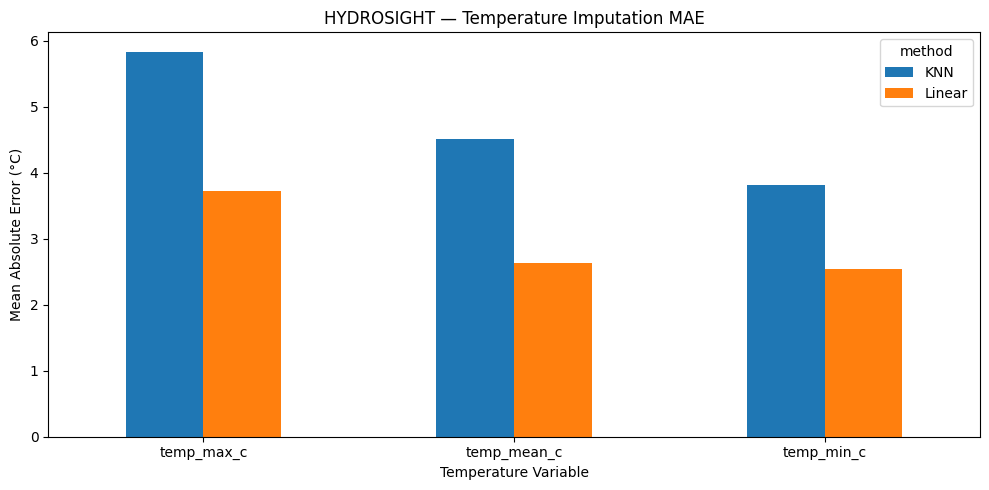

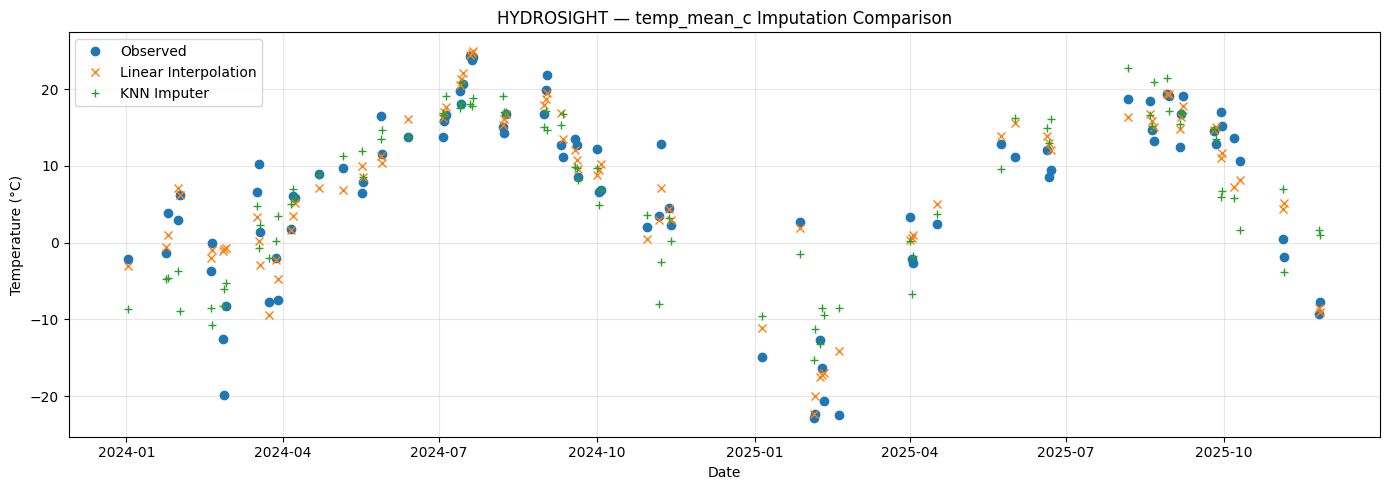

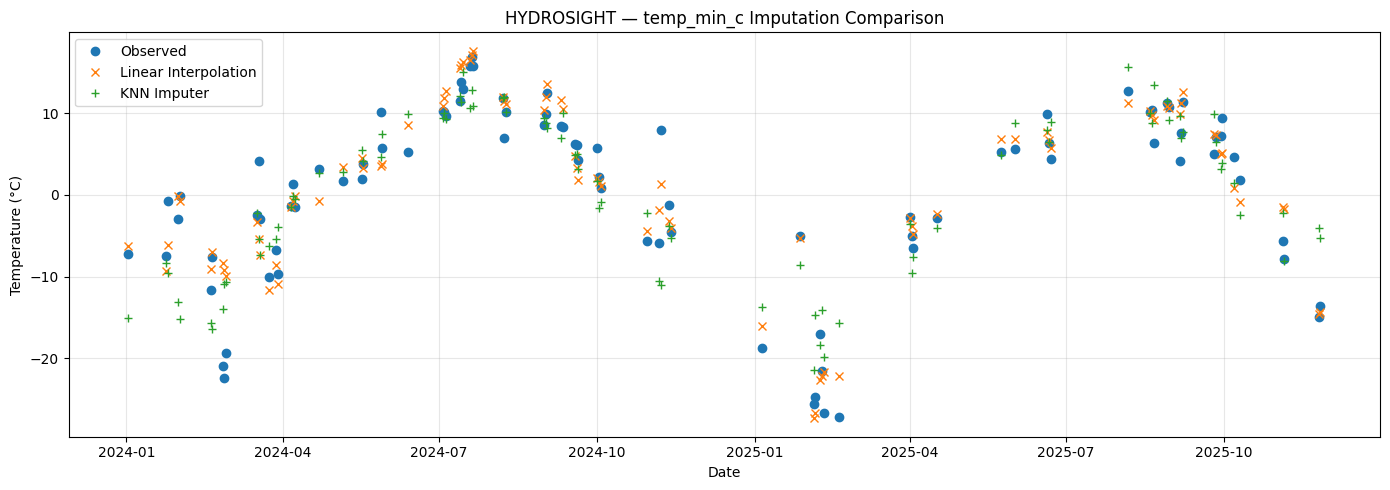

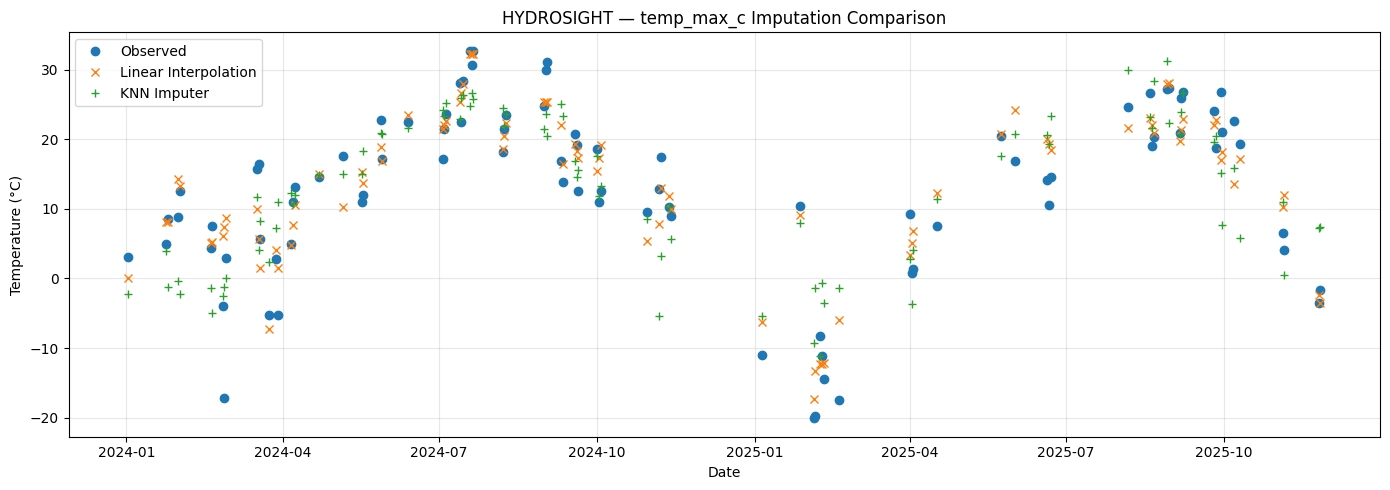

In [210]:
# Compare mean absolute errors
mae_comparison = metrics.pivot(
    index="variable",
    columns="method",
    values="MAE_C"
)

mae_comparison.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("HYDROSIGHT — Temperature Imputation MAE")
plt.ylabel("Mean Absolute Error (°C)")
plt.xlabel("Temperature Variable")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Compare observed and estimated temperatures
comparison = comparison.sort_values("date")

for column in temperature_columns:
    plt.figure(figsize=(14, 5))

    plt.plot(
        comparison["date"],
        comparison[column],
        "o",
        label="Observed"
    )

    plt.plot(
        comparison["date"],
        comparison[f"{column}_linear"],
        "x",
        label="Linear Interpolation"
    )

    plt.plot(
        comparison["date"],
        comparison[f"{column}_knn"],
        "+",
        label="KNN Imputer"
    )

    plt.title(f"HYDROSIGHT — {column} Imputation Comparison")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [211]:
# Evaluate freeze-thaw event preservation
actual_freeze_thaw = (
    (weather_actual.loc[selected_positions, "temp_min_c"] < 0)
    & (weather_actual.loc[selected_positions, "temp_max_c"] > 0)
)

print("=== FREEZE-THAW VALIDATION ===")

for method_name, dataset in [
    ("Linear", weather_linear),
    ("KNN", weather_knn)
]:
    predicted_freeze_thaw = (
        (dataset.loc[selected_positions, "temp_min_c"] < 0)
        & (dataset.loc[selected_positions, "temp_max_c"] > 0)
    )

    print(f"\nMethod: {method_name}")
    print("Actual freeze-thaw events:", actual_freeze_thaw.sum())
    print("Correct classifications:",
          (predicted_freeze_thaw == actual_freeze_thaw).sum())
    print("Missed events:",
          (actual_freeze_thaw & ~predicted_freeze_thaw).sum())
    print("False events:",
          (~actual_freeze_thaw & predicted_freeze_thaw).sum())

=== FREEZE-THAW VALIDATION ===

Method: Linear
Actual freeze-thaw events: 24
Correct classifications: 83
Missed events: 0
False events: 7

Method: KNN
Actual freeze-thaw events: 24
Correct classifications: 72
Missed events: 8
False events: 10


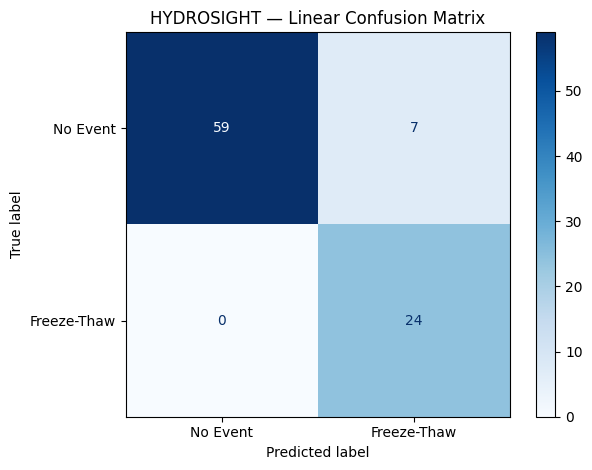

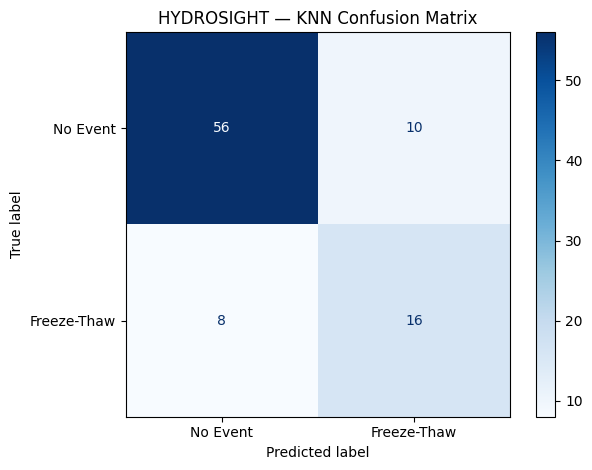

=== FREEZE-THAW CLASSIFICATION PERFORMANCE (%) ===


,Accuracy,Precision,Recall,F1-score
Method,,,,
Linear,92.22,77.42,100.00,87.27
KNN,80.00,61.54,66.67,64.00


In [212]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# Define observed freeze-thaw events
actual_events = (
    (weather_actual.loc[selected_positions, "temp_min_c"] < 0)
    & (weather_actual.loc[selected_positions, "temp_max_c"] > 0)
)

results = []

# Evaluate both imputation methods
for method_name, dataset in [
    ("Linear", weather_linear),
    ("KNN", weather_knn)
]:
    predicted_events = (
        (dataset.loc[selected_positions, "temp_min_c"] < 0)
        & (dataset.loc[selected_positions, "temp_max_c"] > 0)
    )

    results.append({
        "Method": method_name,
        "Accuracy": accuracy_score(actual_events, predicted_events),
        "Precision": precision_score(actual_events, predicted_events, zero_division=0),
        "Recall": recall_score(actual_events, predicted_events, zero_division=0),
        "F1-score": f1_score(actual_events, predicted_events, zero_division=0)
    })

    # Display confusion matrix
    cm = confusion_matrix(
        actual_events,
        predicted_events,
        labels=[False, True]
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Event", "Freeze-Thaw"]
    )

    display_matrix.plot(cmap="Blues", values_format="d")
    plt.title(f"HYDROSIGHT — {method_name} Confusion Matrix")
    plt.tight_layout()
    plt.show()

# Display performance summary
performance = pd.DataFrame(results).set_index("Method")

print("=== FREEZE-THAW CLASSIFICATION PERFORMANCE (%) ===")
display((performance * 100).round(2))

### Comparaison des méthodes d'imputation des températures — Interpolation linéaire et KNN

**Objectif**

L'analyse des données météorologiques de Calgary (2016–2025) a révélé des valeurs manquantes dans les températures moyennes, minimales et maximales, avec des lacunes pouvant atteindre trois jours consécutifs.

Deux méthodes ont été évaluées afin de déterminer laquelle permet de reconstruire les températures manquantes avec le moins d'erreurs :

- **Interpolation linéaire :** estimation à partir des températures connues avant et après la lacune.
- **KNN Imputer (5 voisins) :** estimation à partir d'observations historiques similaires, en tenant compte notamment de la saisonnalité.

**Méthodologie**

Un total de **90 journées réelles de 2024–2025** a été sélectionné. Les trois températures ont été temporairement masquées, soit 270 valeurs à reconstruire, avec des lacunes de 1, 2 et 3 jours. Les observations originales ont été conservées pour mesurer les erreurs.

Le KNN a été ajusté sur les données historiques de 2016–2023. Les deux méthodes ont été évaluées sur les mêmes journées.

**Résultats**

| Variable | MAE linéaire | MAE KNN |
|---|---:|---:|
| Température moyenne | **2,632 °C** | 4,510 °C |
| Température minimale | **2,549 °C** | 3,814 °C |
| Température maximale | **3,726 °C** | 5,838 °C |

L'interpolation linéaire présente les erreurs moyennes les plus faibles pour les trois variables. Elle obtient également de meilleurs résultats au RMSE.

La préservation des événements de gel-dégel a aussi été évaluée :

| Métrique | Linéaire | KNN |
|---|---:|---:|
| Accuracy | **92,22 %** | 80,00 % |
| Recall | **100,00 %** | 66,67 % |
| F1-score | **87,27 %** | 64,00 % |

L'interpolation linéaire a détecté les 24 événements réels de gel-dégel, mais a également généré 7 faux événements. Certaines erreurs ponctuelles de température demeurent importantes.

**Décision**

L'**interpolation linéaire est retenue** pour reconstruire les lacunes historiques de température de **trois jours consécutifs ou moins**, lorsque des observations réelles sont disponibles avant et après la lacune.

Ce choix repose sur sa meilleure précision moyenne, sa capacité à préserver les événements de gel-dégel dans l'expérience et sa simplicité d'application.

Les valeurs estimées devront rester identifiables et la méthode devra respecter la disponibilité temporelle des observations pour éviter toute fuite de données futures.

In [213]:
import pandas as pd

weather_review = df.loc[
    pd.to_datetime(df["date"]).dt.year.between(2016, 2025)
].copy()

weather_review["date"] = pd.to_datetime(weather_review["date"])
weather_review = weather_review.sort_values("date").reset_index(drop=True)

for column in ["precip_mm", "snow_cm"]:
    missing = weather_review[column].isna()

    gaps = (
        weather_review.loc[missing, ["date", column]]
        .assign(
            previous_value=weather_review[column].shift(1)[missing].values,
            next_value=weather_review[column].shift(-1)[missing].values
        )
    )

    print(f"\n=== MISSING VALUES: {column} ===")
    print(f"Missing observations: {missing.sum()}")

    display(gaps)


=== MISSING VALUES: precip_mm ===
Missing observations: 18


,date,precip_mm,previous_value,next_value
229,2016-08-17,NaN,0.0,0.4
289,2016-10-16,NaN,1.0,1.0
344,2016-12-10,NaN,0.4,0.2
663,2017-10-25,NaN,0.0,0.0
676,2017-11-07,NaN,0.0,0.0
917,2018-07-06,NaN,0.0,0.0
1211,2019-04-26,NaN,0.0,13.6
1380,2019-10-12,NaN,0.0,0.0
1463,2020-01-03,NaN,1.8,0.5
1957,2021-05-11,NaN,0.0,0.0



=== MISSING VALUES: snow_cm ===
Missing observations: 67


,date,snow_cm,previous_value,next_value
116,2016-04-26,NaN,0.0,0.0
151,2016-05-31,NaN,0.0,0.0
210,2016-07-29,NaN,0.0,0.0
229,2016-08-17,NaN,0.0,0.0
241,2016-08-29,NaN,0.0,0.0
...,...,...,...,...
3140,2024-08-06,NaN,0.0,NaN
3141,2024-08-07,NaN,NaN,0.0
3484,2025-07-16,NaN,0.0,0.0
3487,2025-07-19,NaN,0.0,0.0


In [214]:
# Analyze seasonal missingness and consecutive snowfall gaps

for column in ["precip_mm", "snow_cm"]:
    missing = weather_review[column].isna()

    monthly_missing = (
        weather_review.loc[missing]
        .groupby(weather_review.loc[missing, "date"].dt.month)
        .size()
        .reindex(range(1, 13), fill_value=0)
    )

    print(f"\n=== MONTHLY MISSINGNESS: {column} ===")
    display(
        monthly_missing.rename_axis("month")
        .reset_index(name="missing_days")
    )

    gap_group = missing.ne(missing.shift()).cumsum()

    missing_gaps = (
        weather_review.loc[missing]
        .groupby(gap_group[missing])
        .agg(
            start_date=("date", "min"),
            end_date=("date", "max"),
            duration_days=("date", "size")
        )
        .sort_values(
            ["duration_days", "start_date"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )

    print(f"\n=== CONSECUTIVE MISSING GAPS: {column} ===")
    display(missing_gaps)


=== MONTHLY MISSINGNESS: precip_mm ===


,month,missing_days
0,1,1
1,2,1
2,3,1
3,4,1
4,5,2
5,6,1
6,7,4
7,8,2
8,9,0
9,10,3



=== CONSECUTIVE MISSING GAPS: precip_mm ===


,start_date,end_date,duration_days
0,2016-08-17,2016-08-17,1
1,2016-10-16,2016-10-16,1
2,2016-12-10,2016-12-10,1
3,2017-10-25,2017-10-25,1
4,2017-11-07,2017-11-07,1
5,2018-07-06,2018-07-06,1
6,2019-04-26,2019-04-26,1
7,2019-10-12,2019-10-12,1
8,2020-01-03,2020-01-03,1
9,2021-05-11,2021-05-11,1



=== MONTHLY MISSINGNESS: snow_cm ===


,month,missing_days
0,1,1
1,2,2
2,3,1
3,4,2
4,5,2
5,6,2
6,7,9
7,8,9
8,9,11
9,10,7



=== CONSECUTIVE MISSING GAPS: snow_cm ===


,start_date,end_date,duration_days
0,2020-11-24,2020-12-08,15
1,2019-08-30,2019-09-02,4
2,2019-09-17,2019-09-20,4
3,2019-09-09,2019-09-11,3
4,2019-10-12,2019-10-14,3
5,2017-07-16,2017-07-17,2
6,2019-10-22,2019-10-23,2
7,2019-11-02,2019-11-03,2
8,2024-08-06,2024-08-07,2
9,2016-04-26,2016-04-26,1


In [215]:
# Inspect weather observations around the longest snowfall gap

critical_period = weather_review.loc[
    weather_review["date"].between("2020-11-17", "2020-12-15"),
    [
        "date",
        "temp_mean_c",
        "temp_min_c",
        "temp_max_c",
        "precip_mm",
        "snow_cm"
    ]
].copy()

print("=== LONGEST SNOWFALL MISSING GAP — WEATHER CONTEXT ===")
display(critical_period)

=== LONGEST SNOWFALL MISSING GAP — WEATHER CONTEXT ===


,date,temp_mean_c,temp_min_c,temp_max_c,precip_mm,snow_cm
1782,2020-11-17,2.3,-4.9,9.4,0.4,0.4
1783,2020-11-18,-2.0,-8.4,4.5,0.8,0.8
1784,2020-11-19,-10.1,-12.0,-8.1,2.0,2.8
1785,2020-11-20,-5.7,-13.4,2.1,0.0,0.0
1786,2020-11-21,-0.1,-5.5,5.4,0.0,0.0
1787,2020-11-22,-4.7,-11.4,2.1,0.0,0.0
1788,2020-11-23,-2.7,-7.2,1.8,0.0,0.0
1789,2020-11-24,-0.5,-9.7,8.7,0.0,NaN
1790,2020-11-25,-1.2,-5.8,3.4,0.0,NaN
1791,2020-11-26,0.6,-5.9,7.1,0.0,NaN


In [216]:
# Check consistency between snowfall and total precipitation

weather_consistency = weather_review.loc[
    weather_review["snow_cm"].notna()
    & weather_review["precip_mm"].notna()
].copy()

snow_without_precipitation = weather_consistency.loc[
    (weather_consistency["snow_cm"] > 0)
    & (weather_consistency["precip_mm"] == 0)
]

print("=== SNOWFALL AND PRECIPITATION CONSISTENCY ===")
print("Valid paired observations:", len(weather_consistency))
print(
    "Snowfall with zero precipitation:",
    len(snow_without_precipitation)
)

display(
    snow_without_precipitation[
        ["date", "temp_mean_c", "precip_mm", "snow_cm"]
    ].head(20)
)

=== SNOWFALL AND PRECIPITATION CONSISTENCY ===
Valid paired observations: 3583
Snowfall with zero precipitation: 0


,date,temp_mean_c,precip_mm,snow_cm


In [217]:
# Inspect weather source columns and metadata

print("=== WEATHER DATASET COLUMNS ===")
print(df.columns.tolist())

print("\n=== WEATHER DATASET SAMPLE ===")
display(df.head(3))

print("\n=== SOURCE METADATA ===")
for name in [
    "weather_source",
    "weather_raw",
    "df_raw",
    "source_columns",
    "column_mapping"
]:
    if name in globals():
        value = globals()[name]
        print(f"\n{name}:")
        if isinstance(value, pd.DataFrame):
            print(value.columns.tolist())
        else:
            print(value)

=== WEATHER DATASET COLUMNS ===
['date', 'station_id', 'temp_mean_c', 'temp_min_c', 'temp_max_c', 'precip_mm', 'snow_cm']

=== WEATHER DATASET SAMPLE ===


,date,station_id,temp_mean_c,temp_min_c,temp_max_c,precip_mm,snow_cm
0,1960-01-01,2205,-12.8,-16.1,-9.4,0.0,0.0
1,1960-01-02,2205,-13.6,-18.3,-8.9,2.5,2.5
2,1960-01-03,2205,-14.2,-24.4,-3.9,5.6,5.6



=== SOURCE METADATA ===


In [218]:
# Classify missing snowfall observations

snow_missing = weather_review["snow_cm"].isna()

zero_precipitation = (
    weather_review["precip_mm"].notna()
    & weather_review["precip_mm"].eq(0)
)

eligible = snow_missing & zero_precipitation
unresolved = snow_missing & ~zero_precipitation

print("=== SNOWFALL MISSING VALUE ASSESSMENT ===")
print("Total missing snowfall:", snow_missing.sum())
print("Zero precipitation recorded:", eligible.sum())
print("Requires further investigation:", unresolved.sum())

print("\n=== UNRESOLVED OBSERVATIONS ===")
display(
    weather_review.loc[
        unresolved,
        ["date", "temp_min_c", "temp_max_c", "precip_mm", "snow_cm"]
    ]
)

=== SNOWFALL MISSING VALUE ASSESSMENT ===
Total missing snowfall: 67
Zero precipitation recorded: 28
Requires further investigation: 39

=== UNRESOLVED OBSERVATIONS ===


,date,temp_min_c,temp_max_c,precip_mm,snow_cm
151,2016-05-31,3.9,17.6,0.2,NaN
210,2016-07-29,12.0,26.1,15.2,NaN
229,2016-08-17,14.0,20.5,NaN,NaN
344,2016-12-10,-23.6,NaN,NaN,NaN
562,2017-07-16,NaN,22.1,1.6,NaN
663,2017-10-25,7.7,NaN,NaN,NaN
676,2017-11-07,-15.2,NaN,NaN,NaN
896,2018-06-15,5.2,17.9,0.8,NaN
917,2018-07-06,13.3,33.2,NaN,NaN
929,2018-07-18,15.7,24.7,0.3,NaN


### Analyse des valeurs manquantes — Précipitations et neige

**Objectif**

L'analyse des données météorologiques de Calgary pour la période 2016–2025 a permis d'identifier des valeurs manquantes dans les précipitations et les chutes de neige. L'objectif était d'évaluer leur répartition et de définir une stratégie de traitement sans introduire de mesures artificielles.

**Analyses réalisées**

Sur les 3 653 journées étudiées, les résultats sont les suivants :

| Variable | Valeurs manquantes | Proportion |
|---|---:|---:|
| Précipitations (`precip_mm`) | 18 | 0,49 % |
| Chutes de neige (`snow_cm`) | 67 | 1,83 % |

L'analyse a porté sur la distribution mensuelle des absences, leur durée consécutive et la cohérence entre les précipitations et les chutes de neige.

Les 18 lacunes de précipitations concernent chacune une seule journée. Pour la neige, la plus longue séquence manquante atteint 15 jours consécutifs, du 24 novembre au 8 décembre 2020.

Parmi les **3 583 observations contenant les deux mesures**, aucune journée ne présente des chutes de neige positives avec des précipitations totales égales à zéro.

L'examen des 67 valeurs manquantes de neige a permis d'identifier :

- **28 journées** où les précipitations totales enregistrées sont nulles.
- **39 journées** pour lesquelles cette condition n'est pas vérifiée ou les précipitations sont également inconnues.

Ces observations fournissent des indices sur les conditions météorologiques, mais ne permettent pas de reconstituer avec certitude toutes les quantités manquantes.

**Décision méthodologique**

Les valeurs manquantes de précipitations et de neige seront **conservées comme inconnues (`NaN`) dans les données météorologiques historiques**, sans suppression de journées ni imputation arbitraire.

Pour la modélisation, des caractéristiques météorologiques agrégées sur des fenêtres temporelles seront utilisées, notamment les cumuls observés sur 30 jours, accompagnés du nombre de journées sans mesure.

Cette stratégie permet de préserver la continuité temporelle, de distinguer les mesures réellement observées des données absentes et de préparer des caractéristiques numériques exploitables sans inventer de précipitations ou de chutes de neige.

**Limite et conclusion**

Les cumuls calculés à partir des observations disponibles ne représentent pas nécessairement les quantités météorologiques totales lorsque certaines journées sont manquantes. Les indicateurs de couverture devront donc être conservés et leur influence évaluée lors de la modélisation.

Cette décision permet de conclure l'analyse exploratoire des précipitations et de la neige tout en reportant le traitement opérationnel des absences à l'étape de préparation des caractéristiques du modèle HYDROSIGHT.

In [219]:
# Create the cleaned weather dataset

import pandas as pd

df_clean = weather_review.copy()
df_clean["date"] = pd.to_datetime(df_clean["date"])
df_clean = df_clean.sort_values("date").reset_index(drop=True)

temperature_columns = ["temp_mean_c", "temp_min_c", "temp_max_c"]

for column in temperature_columns:
    missing_before = df_clean[column].isna()

    estimated = df_clean[column].interpolate(
        method="linear",
        limit=3,
        limit_area="inside"
    )

    # Keep gaps longer than three consecutive days unchanged
    gap_groups = missing_before.ne(missing_before.shift()).cumsum()
    gap_lengths = missing_before.groupby(gap_groups).transform("sum")
    eligible = missing_before & gap_lengths.le(3)

    df_clean.loc[eligible, column] = estimated.loc[eligible]

    df_clean[f"{column}_imputed"] = (
        eligible & df_clean[column].notna()
    ).astype(int)

# Validate chronological and physical consistency
assert df_clean["date"].is_unique
assert df_clean["date"].is_monotonic_increasing

complete_temperatures = df_clean[temperature_columns].notna().all(axis=1)

valid_temperatures = (
    (df_clean["temp_min_c"] <= df_clean["temp_mean_c"])
    & (df_clean["temp_mean_c"] <= df_clean["temp_max_c"])
)

print("=== CLEAN WEATHER DATASET VALIDATION ===")
print("Records:", len(df_clean))
print("\nMissing values:")
print(df_clean[temperature_columns + ["precip_mm", "snow_cm"]].isna().sum())

print("\nInterpolated temperatures:")
print(df_clean[[f"{column}_imputed" for column in temperature_columns]].sum())

print("\nTemperature consistency violations:",
      (complete_temperatures & ~valid_temperatures).sum())

=== CLEAN WEATHER DATASET VALIDATION ===
Records: 3653

Missing values:
temp_mean_c     0
temp_min_c      0
temp_max_c      0
precip_mm      18
snow_cm        67
dtype: int64

Interpolated temperatures:
temp_mean_c_imputed    94
temp_min_c_imputed     90
temp_max_c_imputed     71
dtype: int64

Temperature consistency violations: 5


In [220]:
# Inspect temperature consistency violations

invalid_mask = (
    (df_clean["temp_min_c"] > df_clean["temp_mean_c"])
    | (df_clean["temp_mean_c"] > df_clean["temp_max_c"])
)

columns = (
    ["date"]
    + temperature_columns
    + [f"{column}_imputed" for column in temperature_columns]
)

print("=== TEMPERATURE CONSISTENCY VIOLATIONS ===")
display(df_clean.loc[invalid_mask, columns])

=== TEMPERATURE CONSISTENCY VIOLATIONS ===


,date,temp_mean_c,temp_min_c,temp_max_c,temp_mean_c_imputed,temp_min_c_imputed,temp_max_c_imputed
509,2017-05-24,15.250000,9.60,12.800000,1,1,0
663,2017-10-25,5.750000,7.70,10.950000,1,0,1
677,2017-11-08,-11.166667,-11.10,-5.533333,1,0,1
755,2018-01-25,-5.950000,-10.35,-7.000000,1,1,0
764,2018-02-03,-17.900000,-22.70,-18.700000,1,1,0


In [221]:
# Enforce temperature consistency for imputed mean values only

invalid_mean = (
    (df_clean["temp_mean_c_imputed"] == 1)
    & (
        (df_clean["temp_mean_c"] < df_clean["temp_min_c"])
        | (df_clean["temp_mean_c"] > df_clean["temp_max_c"])
    )
)

corrected_count = int(invalid_mean.sum())

df_clean.loc[invalid_mean, "temp_mean_c"] = (
    df_clean.loc[invalid_mean, "temp_mean_c"].clip(
        lower=df_clean.loc[invalid_mean, "temp_min_c"],
        upper=df_clean.loc[invalid_mean, "temp_max_c"]
    )
)

remaining_violations = (
    (df_clean["temp_min_c"] > df_clean["temp_mean_c"])
    | (df_clean["temp_mean_c"] > df_clean["temp_max_c"])
)

print("=== TEMPERATURE CONSISTENCY CORRECTION ===")
print("Corrected imputed values:", corrected_count)
print("Remaining violations:", int(remaining_violations.sum()))

assert not remaining_violations.any()

=== TEMPERATURE CONSISTENCY CORRECTION ===
Corrected imputed values: 5
Remaining violations: 0


In [222]:
def save_processed_data(df):
    # Export cleaned water main break records
    # Export cleaned water main break records as timestamped JSONL
    output_dir = ROOT_DIR / "data" / "processed" / "weather"
    output_dir.mkdir(parents=True, exist_ok=True)

    timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
    output_file = output_dir / f"daily_weather_calgary_{timestamp}.jsonl"

    df.to_json(
        output_file,
        orient="records",
        lines=True,
        date_format="iso",
        force_ascii=False
    )

    # Download file to local computer
    from google.colab import files as colab_files
    colab_files.download(str(output_file))

    print(f"Cleaned dataset saved: {output_file}")
    print(f"Exported records: {len(df)}")

In [223]:
from datetime import datetime, timezone
save_processed_data(df_clean)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cleaned dataset saved: /content/HYDROSIGHT/data/processed/weather/daily_weather_calgary_20261101T185433Z.jsonl
Exported records: 3653
